# Results and limitations

Summarize the application’s coverage and the archived forecasting evidence.

In [1]:
import sys
from pathlib import Path

HERE = Path.cwd().resolve()
NB = HERE if (HERE / 'mandi_notes.py').is_file() else HERE / 'Notebook'
sys.path.insert(0, str(NB))
from mandi_notes import *

,Count
Published crop coverage,56
Published states and UTs,33
Published market locations,7060
Current-batch daily estimates,393
Future estimates,1179
Trading candidates,3680
Saved directed route options,544


Published issue: 2026-11-13T21:28:46.252788+05:30


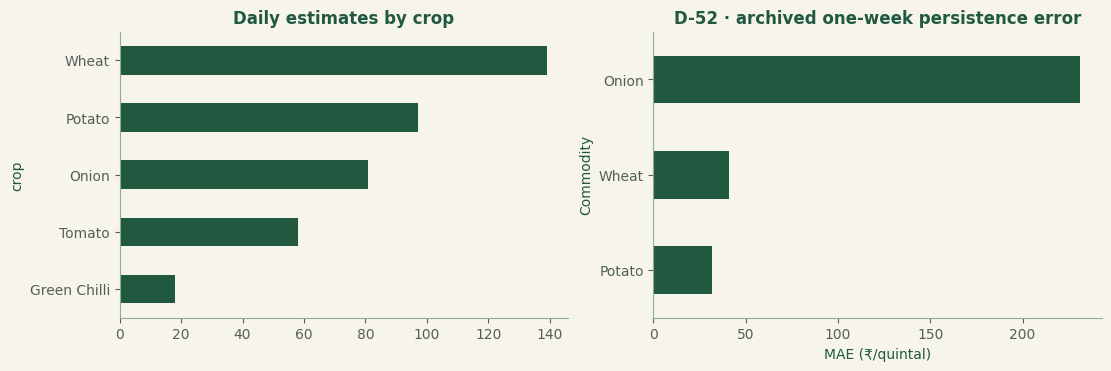

In [2]:
from Code.intelligence.states import state_id
snap = publication()
status = auxiliary("last_success",snap)
forecast = predictions(snap)
registry = pd.read_parquet(DAILY/"releases"/snap["release"]["release"]/"registry.parquet")
stats = {
    "Published crop coverage":registry.crop.nunique(),
    "Published states and UTs":registry.state.map(state_id).nunique(),
    "Published market locations":len(registry[["state","district","market"]].drop_duplicates()),
    "Current-batch daily estimates":len(forecast),
    "Future estimates":status["future_forecast_count"],
    "Trading candidates":status["strategy_count"],
    "Saved directed route options":len(pd.read_parquet(INTEL/"phase3/roads_v1/routes.parquet",columns=["road_km"])),
}
display(pd.Series(stats,name="Count").to_frame())
print("Published issue:",snap["batch"]["issue"])
fig, axes = plt.subplots(1,2,figsize=(11,3.6),layout="constrained")
forecast.crop.value_counts().sort_values().plot.barh(ax=axes[0],title="Daily estimates by crop")
d52 = pd.read_csv(CANDIDATE/"exp_candidate_v1/persistence_test_d52/run/by_crop.csv")
headline = d52.query("design == 'faq_only' and horizon == 1").set_index("Commodity").mae
headline.sort_values().plot.barh(ax=axes[1],title="D-52 · archived one-week persistence error",xlabel="MAE (₹/quintal)")
plt.show()

In [3]:
arrivals = pd.read_csv(DATA/"modelling/phase09_models/test_2021_2022/test_metrics.csv")
primary_annual = arrivals[(arrivals.population == "primary") & arrivals.period.isin(["test_2021", "test_2022"])]
scores = primary_annual.rel_log_mae_improvement_pct
print(f"Phase 9 arrivals test · {len(scores)} primary annual test cells · {scores.min():.1f}% to {scores.max():.1f}% improvement in log MAE.")
future_manifest = read_json(INTEL/"phase3/future_v1/manifest.json")
display(pd.DataFrame(future_manifest["choices"]).groupby(["selected_on_2017","serving_model"]).size().to_frame("Study crop-horizon cells"))

Phase 9 arrivals test · 18 primary annual test cells · 2.3% to 13.5% improvement in log MAE.


,,Study crop-horizon cells
selected_on_2017,serving_model,
hist_gradient_boosting,persistence,16
moving_average_7obs,persistence,21
persistence,persistence,15
ridge,persistence,7
seasonal_naive_7d,persistence,1


Historical weather availability, revised reporting dates and simulated storage parameters limit interpretation. Price persistence remains deployed. The arrivals experiment is historical and the daily source lacks validated arrivals inputs. Current forecast coverage can expire or change as reports arrive.

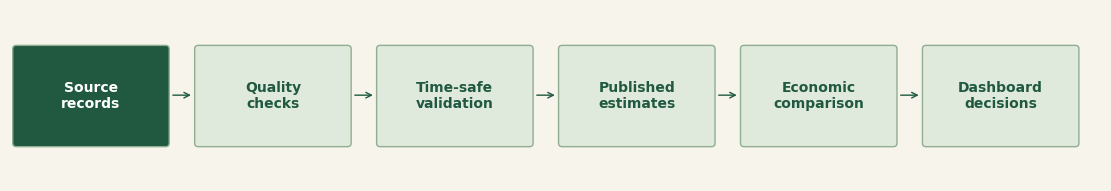

In [4]:
diagram(["Source\nrecords", "Quality\nchecks", "Time-safe\nvalidation", "Published\nestimates", "Economic\ncomparison", "Dashboard\ndecisions"])

**Takeaway** · The project turns audited reports into explainable plans. Coverage, historical error and modeled logistics bound those plans.

**Next** · Reopen Notebook 03 for data exploration or Notebook 12 for a worked journey.